# Mortgage Refinancing Exposure Analytics
# 1. PROJECT OVERVIEW
## 1.1. Project Objective and Business Questions

This project analyses how changes in prevailing mortgage rates may affect voluntary prepayment exposure across a portfolio of 30-year fixed-rate mortgages.

The analysis uses Freddie Mac Single-Family Loan-Level Dataset samples for origination vintages 2019–2025, combined with Freddie Mac 30-Year Primary Mortgage Market Survey (PMMS) rates.

The project focuses on three business questions:

- How does voluntary payoff behaviour change as refinancing incentive increases?
- How much active mortgage UPB becomes rate-sensitive under hypothetical declines in market mortgage rates?
- Which portfolio segments contain the highest concentration of rate-sensitive exposure?

This project is designed as portfolio exposure analytics rather than individual borrower prepayment prediction.

## 1.2. Analytical Scope

- Origination vintages: 2019–2025
- Performance observations: through March 2026
- Mortgage population: 30-year fixed-rate mortgages
- Market benchmark: Freddie Mac 30-Year PMMS
- Main behavioural event: voluntary payoff
- Scenario analysis: Current, -50 bps, -100 bps, -150 bps

## 1.3. Key Analytical Principle

- Refinancing incentive is defined as:

    - **Rate Incentive = Current Mortgage Rate - Prevailing 30-Year Market Rate**

- A positive value indicates that the borrower's current mortgage rate is above the prevailing market benchmark, indicating a greater economic incentive to refinance or otherwise voluntarily prepay.

# 2. ENVIRONMENT AND CONFIGURATION 

## 2.1. Libraries and Project Configuration

Import the libraries used for data preparation, analysis, and visualization, and define the project paths and origination vintages used throughout the notebook.

In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [0]:
RAW_PATH = Path(
    "/Volumes/mortgage_refinancing/mortgage_analysis/raw_data"
)

VINTAGES = list(range(2019, 2026))

PMMS_PATH = RAW_PATH / "PMMS_history.csv"

## 2.2. Official Freddie Mac File Schemas

The Freddie Mac Single-Family Loan-Level Dataset files are pipe-delimited text files without embedded column headers.

Column names are therefore assigned explicitly using the official Release 47 File Layout (effective July 2026).

In [0]:
orig_cols = [
    "classic_fico",
    "first_payment_date",
    "first_time_homebuyer_indicator",
    "maturity_date",
    "msa",
    "mi_percentage",
    "number_of_units",
    "occupancy_status",
    "original_cltv",
    "original_dti",
    "original_upb",
    "original_ltv",
    "original_interest_rate",
    "channel",
    "prepayment_penalty_indicator",
    "amortization_type",
    "property_state",
    "property_type",
    "postal_code",
    "loan_identifier",
    "loan_purpose",
    "original_loan_term",
    "number_of_borrowers",
    "seller_name",
    "super_conforming_flag",
    "pre_harp_loan_identifier",
    "special_eligibility_program",
    "harp_indicator",
    "property_valuation_method",
    "interest_only_indicator",
    "vantagescore_4"
]

In [0]:
len(orig_cols)

31

In [0]:
perf_cols = [
    "loan_identifier",
    "period",
    "current_actual_upb",
    "current_loan_delinquency_status",
    "loan_age",
    "remaining_months_to_legal_maturity",
    "defect_settlement_date",
    "modification_flag",
    "zero_balance_code",
    "zero_balance_effective_date",
    "current_interest_rate",
    "current_non_interest_bearing_upb",
    "ddlpi",
    "mi_recoveries",
    "net_sales_proceeds",
    "non_mi_recoveries",
    "total_expenses",
    "legal_costs",
    "maintenance_preservation_costs",
    "taxes_and_insurance",
    "misc_expenses",
    "actual_loss",
    "cumulative_modification_costs",
    "interest_rate_step_indicator",
    "payment_deferral_flag",
    "estimated_ltv",
    "zero_balance_removal_upb",
    "delinquent_accrued_interest",
    "delinquency_due_to_disaster",
    "borrower_assistance_plan",
    "current_period_modification_costs",
    "current_interest_bearing_upb",
    "mi_cancellation_indicator",
    "servicer_name",
    "bankruptcy_cramdown_costs"
]

In [0]:
len(perf_cols)

35

## 2.3. Analytical Column Selection

Only fields required for portfolio filtering, historical payoff analysis, rate-incentive measurement, and exposure segmentation are loaded from the raw files.

This reduces memory usage while retaining the variables required for the analytical workflow.

In [0]:
orig_usecols = [
    "classic_fico",
    "occupancy_status",
    "original_dti",
    "original_upb",
    "original_ltv",
    "original_interest_rate",
    "amortization_type",
    "property_state",
    "loan_identifier",
    "loan_purpose",
    "original_loan_term",
    "number_of_borrowers"
]

perf_usecols = [
    "loan_identifier",
    "period",
    "current_actual_upb",
    "current_loan_delinquency_status",
    "loan_age",
    "remaining_months_to_legal_maturity",
    "zero_balance_code",
    "zero_balance_effective_date",
    "current_interest_rate",
    "estimated_ltv"
]

In [0]:
print("Origination columns:", len(orig_cols))
print("Performance columns:", len(perf_cols))
print("Origination selected:", len(orig_usecols))
print("Performance selected:", len(perf_usecols))

Origination columns: 31
Performance columns: 35
Origination selected: 12
Performance selected: 10


# 3. ORIGINATION DATA INGESTION 

## 3.1. Validate Raw Files

Before loading the full multi-vintage dataset, validate that all expected origination and performance files are available and that their column counts match the official Freddie Mac Release 47 file layout.

This check helps detect missing files or schema misalignment before the ingestion pipeline is executed.

In [0]:
for vintage in VINTAGES:
    orig_path = RAW_PATH / f"sample_orig_{vintage}.txt"
    perf_path = RAW_PATH / f"sample_perf_{vintage}.txt"

    print(
        vintage,
        "| Origination:", orig_path.exists(),
        "| Performance:", perf_path.exists()
    )

2019 | Origination: True | Performance: True
2020 | Origination: True | Performance: True
2021 | Origination: True | Performance: True
2022 | Origination: True | Performance: True
2023 | Origination: True | Performance: True
2024 | Origination: True | Performance: True
2025 | Origination: True | Performance: True


In [0]:
schema_check = []

for vintage in VINTAGES:
    orig_path = RAW_PATH / f"sample_orig_{vintage}.txt"
    perf_path = RAW_PATH / f"sample_perf_{vintage}.txt"

    orig_sample = pd.read_csv(
        orig_path,
        sep="|",
        header=None,
        nrows=1
    )

    perf_sample = pd.read_csv(
        perf_path,
        sep="|",
        header=None,
        nrows=1
    )

    schema_check.append({
        "vintage": vintage,
        "orig_columns": orig_sample.shape[1],
        "perf_columns": perf_sample.shape[1]
    })

schema_check = pd.DataFrame(schema_check)

schema_check

,vintage,orig_columns,perf_columns
0,2019,31,35
1,2020,31,35
2,2021,31,35
3,2022,31,35
4,2023,31,35
5,2024,31,35
6,2025,31,35


In [0]:
schema_check["orig_schema_valid"] = (
    schema_check["orig_columns"] == len(orig_cols)
)

schema_check["perf_schema_valid"] = (
    schema_check["perf_columns"] == len(perf_cols)
)

schema_check

,vintage,orig_columns,perf_columns,orig_schema_valid,perf_schema_valid
0,2019,31,35,True,True
1,2020,31,35,True,True
2,2021,31,35,True,True
3,2022,31,35,True,True
4,2023,31,35,True,True
5,2024,31,35,True,True
6,2025,31,35,True,True


In [0]:
assert schema_check["orig_schema_valid"].all(), \
    "Origination schema mismatch detected."

assert schema_check["perf_schema_valid"].all(), \
    "Performance schema mismatch detected."

print("PASS: All Freddie Mac files match the expected Release 47 schema.")

PASS: All Freddie Mac files match the expected Release 47 schema.


## 3.2. Define Origination Ingestion Pipeline

A reusable loading function is used to apply the same schema, column selection, and cleaning rules consistently across all origination vintages.

In [0]:
def load_origination(vintage):
    path = RAW_PATH / f"sample_orig_{vintage}.txt"

    df = pd.read_csv(
        path,
        sep="|",
        header=None,
        names=orig_cols,
        usecols=orig_usecols,
        dtype=str
    )

    df["vintage"] = vintage

    return df

## 3.3. Clean Origination Data

Raw values are converted into analytical representations using the Freddie Mac file definitions.

Freddie Mac sentinel values representing unavailable information are converted to missing values before analytical numeric fields are converted to numeric types.

In [0]:
def clean_origination(df):
    df = df.copy()

    # Freddie Mac sentinel values
    df["classic_fico"] = df["classic_fico"].replace("9999", np.nan)
    df["original_dti"] = df["original_dti"].replace("999", np.nan)

    return df

In [0]:
orig_numeric_cols = [
    "classic_fico",
    "original_dti",
    "original_upb",
    "original_ltv",
    "original_interest_rate",
    "original_loan_term",
    "number_of_borrowers"
]

In [0]:
def clean_origination(df):
    df = df.copy()

    # Convert Freddie Mac sentinel values to missing values
    df["classic_fico"] = df["classic_fico"].replace("9999", np.nan)
    df["original_dti"] = df["original_dti"].replace("999", np.nan)

    # Convert analytical numeric fields
    df[orig_numeric_cols] = df[orig_numeric_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    return df

## 3.4. Load All Origination Vintages

Apply the reusable ingestion and cleaning pipeline consistently across the 2019–2025 origination samples and combine them into a single analytical dataset.

A vintage identifier is retained to support cohort-level validation and analysis.

In [0]:
orig_frames = []

for vintage in VINTAGES:
    df = load_origination(vintage)
    df = clean_origination(df)

    orig_frames.append(df)

orig = pd.concat(
    orig_frames,
    ignore_index=True
)

In [0]:
print("Rows:", len(orig))
print("Columns:", orig.shape[1])
print("Unique loans:", orig["loan_identifier"].nunique())
print("Duplicate loan IDs:", orig["loan_identifier"].duplicated().sum())

Rows: 350000
Columns: 13
Unique loans: 350000
Duplicate loan IDs: 0


In [0]:
orig_vintage_check = (
    orig.groupby("vintage")
        .agg(
            rows=("loan_identifier", "size"),
            unique_loans=("loan_identifier", "nunique")
        )
        .reset_index()
)

orig_vintage_check

,vintage,rows,unique_loans
0,2019,50000,50000
1,2020,50000,50000
2,2021,50000,50000
3,2022,50000,50000
4,2023,50000,50000
5,2024,50000,50000
6,2025,50000,50000


In [0]:
assert len(orig) == 350_000, \
    "Unexpected total origination row count."

assert orig["loan_identifier"].is_unique, \
    "Duplicate loan identifiers detected."

assert (orig_vintage_check["rows"] == 50_000).all(), \
    "Unexpected vintage sample size."

print("PASS: Multi-vintage origination dataset loaded successfully.")

PASS: Multi-vintage origination dataset loaded successfully.


# 4. ORIGINATION DATA QUALITY

The combined origination dataset is reviewed for missing values, numeric distributions, and consistency across vintages before defining the final analytical mortgage population.

## 4.1. Missing Values

In [0]:
orig_missing = (
    orig.isna()
        .sum()
        .to_frame("missing_count")
)

orig_missing["missing_pct"] = (
    orig_missing["missing_count"] / len(orig) * 100
).round(2)

orig_missing.sort_values("missing_pct", ascending=False)

,missing_count,missing_pct
classic_fico,96,0.03
original_dti,45,0.01
occupancy_status,0,0.00
original_upb,0,0.00
original_ltv,0,0.00
original_interest_rate,0,0.00
amortization_type,0,0.00
property_state,0,0.00
loan_identifier,0,0.00
loan_purpose,0,0.00


## 4.2. Validate Numeric Ranges

Review the distributions and observed ranges of key numeric fields to identify values that may require additional investigation before analysis.

In [0]:
orig[
    [
        "classic_fico",
        "original_dti",
        "original_upb",
        "original_ltv",
        "original_interest_rate",
        "original_loan_term",
        "number_of_borrowers"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
classic_fico,349904.0,751.513890,44.553571,300.000,722.000,760.00,788.000,848.00
original_dti,349955.0,36.162504,9.583951,1.000,29.000,38.00,44.000,65.00
original_upb,350000.0,304283.380000,166265.917106,11000.000,180000.000,271000.00,398000.000,2300000.00
original_ltv,350000.0,73.412720,18.583272,3.000,63.000,79.00,90.000,365.00
original_interest_rate,350000.0,5.067324,1.676372,1.625,3.375,5.25,6.625,9.18
original_loan_term,350000.0,335.292849,60.259824,85.000,360.000,360.00,360.000,360.00
number_of_borrowers,350000.0,1.476391,0.530389,1.000,1.000,1.00,2.000,5.00


## 4.3. Check Consistency Across Vintages

Compare selected data-quality and portfolio characteristics across origination vintages to confirm consistent sample coverage and identify meaningful cohort differences.

In [0]:
orig_quality_by_vintage = (
    orig.groupby("vintage")
        .agg(
            loans=("loan_identifier", "size"),
            missing_fico=("classic_fico", lambda x: x.isna().sum()),
            missing_dti=("original_dti", lambda x: x.isna().sum()),
            avg_interest_rate=("original_interest_rate", "mean"),
            avg_original_ltv=("original_ltv", "mean"),
            avg_original_upb=("original_upb", "mean")
        )
        .round(2)
)

orig_quality_by_vintage

,loans,missing_fico,missing_dti,avg_interest_rate,avg_original_ltv,avg_original_upb
vintage,,,,,,
2019,50000,18,31,4.24,75.64,254574.78
2020,50000,7,0,3.20,70.78,287504.26
2021,50000,7,8,2.97,69.39,288075.42
2022,50000,8,3,5.09,73.85,299311.56
2023,50000,17,3,6.74,75.57,311174.64
2024,50000,20,0,6.69,74.84,338959.34
2025,50000,19,0,6.55,73.80,350383.66


# 5. ANALYTICAL MORTGAGE POPULATION 

## 5.1. Population Design

To ensure a consistent comparison between borrower mortgage rates and the market benchmark, the analytical population is restricted to 30-year fixed-rate mortgages (FRMs).

The project uses Freddie Mac's 30-Year PMMS as the market-rate benchmark. Restricting the population to loans with the same fixed-rate structure and contractual term improves comparability when calculating refinancing incentive.

Loans outside this population are not treated as invalid records; they are excluded because they are outside the analytical scope of this study.

## 5.2. Apply the 30-Year FRM Filter

In [0]:
orig_30yr = orig[
    (orig["amortization_type"] == "FRM") &
    (orig["original_loan_term"] == 360)
].copy()

In [0]:
print("Full origination sample:", len(orig))
print("30-year FRM loans:", len(orig_30yr))
print(
    "30-year FRM share:",
    round(len(orig_30yr) / len(orig) * 100, 2),
    "%"
)

Full origination sample: 350000
30-year FRM loans: 295754
30-year FRM share: 84.5 %


- The 30-year FRM restriction retains 84.5% of the original sample, providing a more comparable analytical population while preserving the majority of available mortgage observations.

## 5.3. Validate Population Coverage Across Vintages

Check whether the 30-year FRM restriction retains meaningful coverage across all origination vintages rather than disproportionately representing a small number of cohorts.

In [0]:
frm_by_vintage = (
    orig.assign(
        is_30yr_frm=(
            (orig["amortization_type"] == "FRM") &
            (orig["original_loan_term"] == 360)
        )
    )
    .groupby("vintage")
    .agg(
        total_loans=("loan_identifier", "size"),
        frm_30yr_loans=("is_30yr_frm", "sum")
    )
)

frm_by_vintage["frm_30yr_share_pct"] = (
    frm_by_vintage["frm_30yr_loans"]
    / frm_by_vintage["total_loans"]
    * 100
).round(2)

frm_by_vintage

,total_loans,frm_30yr_loans,frm_30yr_share_pct
vintage,,,
2019,50000,41250,82.50
2020,50000,36536,73.07
2021,50000,37041,74.08
2022,50000,43697,87.39
2023,50000,46686,93.37
2024,50000,46362,92.72
2025,50000,44182,88.36


- 84.5% of the 350,000 loans in the selected 2019–2025 Freddie Mac sample vintages satisfy this project's 30-year FRM filter.

In [0]:
assert orig_30yr["loan_identifier"].is_unique, \
    "Duplicate loan identifiers detected in 30-year FRM population."

assert orig_30yr["loan_identifier"].notna().all(), \
    "Missing loan identifiers detected."

print("PASS: 30-year FRM analytical population created successfully.")

PASS: 30-year FRM analytical population created successfully.


# 6. MONTHLY PERFORMANCE DATA

## 6.1. Define the Performance Data Pipeline

Freddie Mac monthly performance files contain repeated observations for each mortgage over time. Each row therefore represents one loan-month rather than one unique mortgage.

Only performance records belonging to the previously defined 30-year FRM analytical population are retained.

In [0]:
def load_performance(vintage):
    path = RAW_PATH / f"sample_perf_{vintage}.txt"

    df = pd.read_csv(
        path,
        sep="|",
        header=None,
        names=perf_cols,
        usecols=perf_usecols,
        dtype=str
    )

    df["vintage"] = vintage

    return df

## 6.2. Clean Monthly Performance Data

Convert selected monthly performance fields into analytical numeric, date, and categorical representations.

The Freddie Mac sentinel value `999` for unavailable Estimated LTV is converted to missing before numeric conversion.

In [0]:
perf_numeric_cols = [
    "current_actual_upb",
    "loan_age",
    "remaining_months_to_legal_maturity",
    "current_interest_rate",
    "estimated_ltv"
]

In [0]:
def clean_performance(df):
    df = df.copy()

    # Sentinel value: 999 = Not Available
    df["estimated_ltv"] = df["estimated_ltv"].replace("999", np.nan)

    # Numeric fields
    df[perf_numeric_cols] = df[perf_numeric_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Dates
    df["period"] = pd.to_datetime(
        df["period"],
        format="%Y%m",
        errors="coerce"
    )

    df["zero_balance_effective_date"] = pd.to_datetime(
        df["zero_balance_effective_date"],
        format="%Y%m",
        errors="coerce"
    )

    # Categorical codes
    category_cols = [
        "current_loan_delinquency_status",
        "zero_balance_code"
    ]

    df[category_cols] = df[category_cols].astype("category")

    df["remaining_months_to_legal_maturity"] = (
    df["remaining_months_to_legal_maturity"].astype("Int64")
    )

    return df

## 6.3. Load the Full Performance History

Load and clean monthly performance data for each vintage, retaining only loans in the 30-year FRM analytical population before combining the vintage-level datasets.

In [0]:
frm_loan_ids = set(orig_30yr["loan_identifier"])

len(frm_loan_ids)

295754

In [0]:
perf_frames = []

for vintage in VINTAGES:
    print(f"Processing {vintage}...")

    df = load_performance(vintage)
    df = clean_performance(df)

    # Keep only loans in the 30-year FRM analytical population
    df = df[df["loan_identifier"].isin(frm_loan_ids)].copy()

    perf_frames.append(df)

    print(
        f"{vintage}: {len(df):,} loan-months | "
        f"{df['loan_identifier'].nunique():,} loans"
    )

Processing 2019...
2019: 1,562,943 loan-months | 41,250 loans
Processing 2020...
2020: 1,831,380 loan-months | 36,536 loans
Processing 2021...
2021: 1,873,772 loan-months | 37,041 loans
Processing 2022...
2022: 1,769,943 loan-months | 43,697 loans
Processing 2023...
2023: 1,362,335 loan-months | 46,686 loans
Processing 2024...
2024: 885,815 loan-months | 46,362 loans
Processing 2025...
2025: 361,069 loan-months | 44,178 loans


In [0]:
perf = pd.concat(
    perf_frames,
    ignore_index=True
)

## 6.4. Validate Performance Coverage

Validate the combined monthly performance dataset and confirm that mortgages in the 30-year FRM origination population are represented in the performance history.

In [0]:
print("Total loan-months:", f"{len(perf):,}")
print("Unique loans:", f"{perf['loan_identifier'].nunique():,}")

duplicate_loan_months = perf.duplicated(
    subset=["loan_identifier", "period"]
).sum()

print("Duplicate loan-months:", duplicate_loan_months)

Total loan-months: 9,647,257
Unique loans: 295,750
Duplicate loan-months: 0


In [0]:
perf_vintage_check = (
    perf.groupby("vintage")
        .agg(
            loan_months=("loan_identifier", "size"),
            unique_loans=("loan_identifier", "nunique"),
            min_period=("period", "min"),
            max_period=("period", "max")
        )
)

perf_vintage_check

,loan_months,unique_loans,min_period,max_period
vintage,,,,
2019,1562943,41250,2019-01-01,2026-03-01
2020,1831380,36536,2020-01-01,2026-03-01
2021,1873772,37041,2021-01-01,2026-03-01
2022,1769943,43697,2022-01-01,2026-03-01
2023,1362335,46686,2023-01-01,2026-03-01
2024,885815,46362,2024-01-01,2026-03-01
2025,361069,44178,2025-01-01,2026-03-01


In [0]:
# Check whether any loans in the 30-year FRM origination population are missing from the performance dataset.

perf_loan_ids = set(perf["loan_identifier"])

missing_perf_loans = orig_30yr[
    ~orig_30yr["loan_identifier"].isin(perf_loan_ids)
]

missing_perf_loans

,classic_fico,occupancy_status,original_dti,original_upb,original_ltv,original_interest_rate,amortization_type,property_state,loan_identifier,loan_purpose,original_loan_term,number_of_borrowers,vintage
340249,785.0,P,30.0,235000,71,5.875,FRM,OH,F25Q40069506,P,360,1,2025
343526,809.0,P,26.0,176000,80,6.125,FRM,FL,F25Q40153455,P,360,2,2025
343894,791.0,P,16.0,425000,59,6.125,FRM,OR,F25Q40163281,P,360,2,2025
344946,764.0,P,30.0,304000,95,7.500,FRM,PA,F25Q40189154,P,360,2,2025


In [0]:
print("30-year FRM loans:", len(orig_30yr))
print("Loans with performance:", perf["loan_identifier"].nunique())
print("Loans without performance:", len(missing_perf_loans))

30-year FRM loans: 295754
Loans with performance: 295750
Loans without performance: 4


In [0]:
missing_perf_loans["vintage"].value_counts()

vintage
2025    4
Name: count, dtype: int64

In [0]:
# Four 2025 origination loans have no corresponding performance records. They remain part of the origination population but do not enter the loan-month analysis.

assert len(missing_perf_loans) == 4
assert (missing_perf_loans["vintage"] == 2025).all()

print("PASS: 4 origination loans have no performance records; all are from the 2025 vintage.")

PASS: 4 origination loans have no performance records; all are from the 2025 vintage.


## 6.5. Define and Validate the Voluntary Payoff Event

Freddie Mac Zero Balance Code `01` represents a prepaid or matured loan (voluntary payoff).

Before using Code `01` as the voluntary-payoff event in the analysis, validate that these events occur well before contractual maturity and that each loan records no more than one such event.

In [0]:
perf["zero_balance_code"].value_counts(dropna=False)

zero_balance_code
NaN    9562772
01       83225
96        1004
09          78
02          66
16          62
15          31
03          19
Name: count, dtype: int64

In [0]:
code01 = perf[
    perf["zero_balance_code"] == "01"
].copy()

print("Code 01 events:", f"{len(code01):,}")
print("Loans with Code 01:", f"{code01['loan_identifier'].nunique():,}")

Code 01 events: 83,225
Loans with Code 01: 83,225


In [0]:
code01_per_loan = (
    code01.groupby("loan_identifier")
          .size()
)

print("Maximum Code 01 events per loan:", code01_per_loan.max())

Maximum Code 01 events per loan: 1


In [0]:
code01_by_vintage = (
    code01.groupby("vintage")
          .agg(
              voluntary_payoffs=("loan_identifier", "size"),
              unique_loans=("loan_identifier", "nunique"),
              median_payoff_age=("loan_age", "median"),
              min_remaining_maturity=(
                  "remaining_months_to_legal_maturity",
                  "min"
              )
          )
)

code01_by_vintage

,voluntary_payoffs,unique_loans,median_payoff_age,min_remaining_maturity
vintage,,,,
2019,29663,29663,17.0,276
2020,14190,14190,16.0,288
2021,7126,7126,25.0,300
2022,8427,8427,25.0,312
2023,12046,12046,19.0,324
2024,8462,8462,13.0,336
2025,3311,3311,6.0,348


- Observed Code 01 events occur well before contractual maturity across all vintages. The minimum remaining term at a Code 01 event is 276 months, supporting the use of Code 01 as a voluntary-payoff proxy in this analytical population.

- However, the dataset does not establish whether each voluntary payoff was specifically caused by refinancing.

In [0]:
perf["voluntary_payoff_flag"] = (
    perf["zero_balance_code"] == "01"
).astype("int8")

In [0]:
assert perf["voluntary_payoff_flag"].sum() == len(code01)

assert (
    perf.groupby("loan_identifier")[
        "voluntary_payoff_flag"
    ].sum().max()
    == 1
)

print("PASS: Voluntary payoff flag validated.")

PASS: Voluntary payoff flag validated.


# 7. BUILD THE LOAN-MONTH ANALYTICAL DATASET

## 7.1. Merge Monthly Performance with Origination Attributes

Merge monthly performance observations with loan-level origination attributes to create the analytical loan-month dataset.

The merge uses `loan_identifier` and `vintage`, with multiple monthly performance observations expected to match one origination record for each mortgage.

In [0]:
loan_month = perf.merge(
    orig_30yr,
    on=["loan_identifier", "vintage"],
    how="left",
    validate="many_to_one"
)

## 7.2. Validate Merge Integrity

In [0]:
print("Performance rows:", f"{len(perf):,}")
print("Merged rows:", f"{len(loan_month):,}")
print(
    "Unique loans:",
    f"{loan_month['loan_identifier'].nunique():,}"
)

assert len(loan_month) == len(perf)

print("PASS: Merge preserved all performance observations.")

Performance rows: 9,647,257
Merged rows: 9,647,257
Unique loans: 295,750
PASS: Merge preserved all performance observations.


In [0]:
merge_check = loan_month[
    [
        "original_upb",
        "original_ltv",
        "original_interest_rate",
        "classic_fico"
    ]
].isna().sum()

merge_check

original_upb                 0
original_ltv                 0
original_interest_rate       0
classic_fico              1947
dtype: int64

In [0]:
merge_missing_check = loan_month[
    [
        "original_upb",
        "original_ltv",
        "original_interest_rate"
    ]
].isna().sum()

merge_missing_check

original_upb              0
original_ltv              0
original_interest_rate    0
dtype: int64

In [0]:
print(
    "Loan-months with missing FICO:",
    f"{loan_month['classic_fico'].isna().sum():,}"
)

Loan-months with missing FICO: 1,947


- All performance observations successfully matched to the required origination attributes. Missing FICO values reflect missing borrower credit-score information already present in the origination data rather than failed merge records.

# 8. PMMS MARKET RATES

## 8.1. Load and Inspect PMMS Data

Freddie Mac's Primary Mortgage Market Survey (PMMS) provides the market mortgage-rate benchmark used in this analysis.

The 30-year fixed-rate series (`pmms30`) is used to maintain consistency with the 30-year FRM analytical population.

In [0]:
pmms = pd.read_csv(PMMS_PATH)

print("Rows:", len(pmms))
print("Columns:", pmms.shape[1])

pmms.head()

Rows: 2894
Columns: 9


,date,pmms30,pmms30p,pmms15,pmms15p,pmms51,pmms51p,pmms51m,pmms51spread
0,4/2/1971,7.33,,NaN,NaN,NaN,NaN,NaN,NaN
1,4/9/1971,7.31,,NaN,NaN,NaN,NaN,NaN,NaN
2,4/16/1971,7.31,,NaN,NaN,NaN,NaN,NaN,NaN
3,4/23/1971,7.31,,NaN,NaN,NaN,NaN,NaN,NaN
4,4/30/1971,7.29,,NaN,NaN,NaN,NaN,NaN,NaN


## 8.2. Prepare Monthly 30-Year PMMS Benchmark

PMMS is reported weekly, while mortgage performance is observed monthly. The weekly 30-year PMMS series is therefore aggregated to a monthly average to create a comparable market-rate benchmark for each loan-month observation.

In [0]:
pmms_clean = pmms[["date", "pmms30"]].copy()

pmms_clean["date"] = pd.to_datetime(
    pmms_clean["date"],
    errors="coerce"
)

pmms_clean = pmms_clean.rename(
    columns={"pmms30": "market_rate_30yr"}
)

In [0]:
print("Rows:", f"{len(pmms_clean):,}")
print("Date range:", pmms_clean["date"].min(), "to", pmms_clean["date"].max())
print("Missing dates:", pmms_clean["date"].isna().sum())
print("Missing rates:", pmms_clean["market_rate_30yr"].isna().sum())

Rows: 2,894
Date range: 1971-04-02 00:00:00 to 2026-09-10 00:00:00
Missing dates: 0
Missing rates: 0


In [0]:
pmms_clean["period"] = (
    pmms_clean["date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

pmms_monthly = (
    pmms_clean
    .groupby("period", as_index=False)["market_rate_30yr"]
    .mean()
)

pmms_monthly["market_rate_30yr"] = (
    pmms_monthly["market_rate_30yr"].round(3)
)

In [0]:
pmms_project = pmms_monthly[
    (pmms_monthly["period"] >= "2019-01-01") &
    (pmms_monthly["period"] <= "2026-03-01")
].copy()

print("Rows:", len(pmms_project))
print(
    "Period range:",
    pmms_project["period"].min(),
    "to",
    pmms_project["period"].max()
)

Rows: 87
Period range: 2019-01-01 00:00:00 to 2026-03-01 00:00:00


## 8.3. Merge Market Rates with Loan-Month Data

Merge the monthly 30-year PMMS benchmark with the loan-month dataset using the reporting period. Each monthly market-rate observation is expected to match multiple mortgage observations within the same period.

In [0]:
loan_month = loan_month.merge(
    pmms_project,
    on="period",
    how="left",
    validate="many_to_one"
)

In [0]:
print("Rows after PMMS merge:", f"{len(loan_month):,}")
print(
    "Missing market rates:",
    f"{loan_month['market_rate_30yr'].isna().sum():,}"
)

assert len(loan_month) == len(perf), \
    "Row count changed after PMMS merge."

assert loan_month["market_rate_30yr"].isna().sum() == 0, \
    "Some loan-months do not have a matching PMMS rate."

print("PASS: PMMS rates merged successfully.")

Rows after PMMS merge: 9,647,257
Missing market rates: 0
PASS: PMMS rates merged successfully.


## 8.4. Calculate Refinancing Incentive

Refinancing incentive measures the difference between a mortgage's current interest rate and the prevailing 30-year market mortgage rate:

**Rate Incentive (bps) = (Current Mortgage Rate − 30-Year PMMS Rate) × 100**

A positive value indicates that the mortgage's current rate is above the market benchmark, implying greater economic incentive to refinance or otherwise voluntarily prepay.

In [0]:
loan_month["rate_incentive_bps"] = (
    (
        loan_month["current_interest_rate"]
        - loan_month["market_rate_30yr"]
    ) * 100
).round(1)

In [0]:
loan_month["rate_incentive_bps"].describe()

count    9.647257e+06
mean    -1.218401e+02
std      1.788031e+02
min     -5.745000e+02
25%     -2.968000e+02
50%     -8.390000e+01
75%      2.840000e+01
max      4.066000e+02
Name: rate_incentive_bps, dtype: float64

In [0]:
assert loan_month["rate_incentive_bps"].notna().all()

print(
    "Rate incentive coverage:",
    f"{loan_month['rate_incentive_bps'].notna().sum():,}",
    "loan-months"
)

print("PASS: Refinancing incentive calculated for all loan-month observations.")

Rate incentive coverage: 9,647,257 loan-months
PASS: Refinancing incentive calculated for all loan-month observations.


# 9. HISTORICAL PREPAYMENT BEHAVIOUR

## 9.1. Positive and Non-Positive Refinancing Incentive

Historical loan-month observations are used to examine whether voluntary payoff behaviour varies with refinancing incentive.

The first comparison separates observations where the mortgage's current interest rate is above the prevailing market rate from observations where it is equal to or below the market rate.

In [0]:
loan_month["positive_incentive_flag"] = (
    loan_month["rate_incentive_bps"] > 0
)

incentive_summary = (
    loan_month
    .groupby("positive_incentive_flag")
    .agg(
        loan_months=("loan_identifier", "size"),
        voluntary_payoffs=("voluntary_payoff_flag", "sum")
    )
    .reset_index()
)

incentive_summary["monthly_payoff_rate"] = (
    incentive_summary["voluntary_payoffs"]
    / incentive_summary["loan_months"]
)

incentive_summary

,positive_incentive_flag,loan_months,voluntary_payoffs,monthly_payoff_rate
0,False,6451216,28238,0.004377
1,True,3196041,54987,0.017205


In [0]:
bins = [
    -np.inf,
    -200, -150, -100, -50, 0,
    25, 50, 75, 100, 125, 150, 200,
    np.inf
]

labels = [
    "<=-200",
    "-200 to -150",
    "-150 to -100",
    "-100 to -50",
    "-50 to 0",
    "0 to 25",
    "25 to 50",
    "50 to 75",
    "75 to 100",
    "100 to 125",
    "125 to 150",
    "150 to 200",
    ">200"
]

loan_month["incentive_band"] = pd.cut(
    loan_month["rate_incentive_bps"],
    bins=bins,
    labels=labels,
    right=False
)

- Historical loan-month observations with a positive refinancing incentive show a materially higher voluntary payoff rate than observations with a non-positive incentive (1.721% vs. 0.438% per month).

- This relationship is descriptive and does not establish that refinancing incentive alone causes voluntary payoff.

## 9.2. Validate the Incentive-Payoff Relationship by Loan Age

Loan age may also influence voluntary payoff behaviour. To assess whether the observed relationship between refinancing incentive and voluntary payoff is driven primarily by loan seasoning, the comparison is repeated within loan-age bands.

In [0]:
band_summary = (
    loan_month
    .groupby("incentive_band", observed=True)
    .agg(
        loan_months=("loan_identifier", "size"),
        voluntary_payoffs=("voluntary_payoff_flag", "sum")
    )
    .reset_index()
)

band_summary["monthly_payoff_rate"] = (
    band_summary["voluntary_payoffs"]
    / band_summary["loan_months"]
)

band_summary

,incentive_band,loan_months,voluntary_payoffs,monthly_payoff_rate
0,<=-200,3583447,14040,0.003918
1,-200 to -150,478746,2412,0.005038
2,-150 to -100,540110,2608,0.004829
3,-100 to -50,724722,3392,0.004680
4,-50 to 0,1117396,5760,0.005155
5,0 to 25,663122,4421,0.006667
6,25 to 50,670519,6516,0.009718
7,50 to 75,571824,8518,0.014896
8,75 to 100,486122,10487,0.021573
9,100 to 125,306406,8667,0.028286


In [0]:
# Loan age may influence voluntary payoff behaviour. Loan-month observations are grouped into seasoning bands to test whether the higher payoff rates associated with positive refinancing incentives persist across different stages of the loan lifecycle.

age_bins = [
    -np.inf,
    6, 12, 24, 36, 48, 60,
    np.inf
]

age_labels = [
    "<6 months",
    "6-11 months",
    "12-23 months",
    "24-35 months",
    "36-47 months",
    "48-59 months",
    "60+ months"
]

loan_month["loan_age_band"] = pd.cut(
    loan_month["loan_age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

In [0]:
# Across the loan-age bands with substantial positive-incentive observations, voluntary payoff rates are generally higher for positive-incentive loans than for non-positive-incentive loans.

# The oldest loan-age bands contain very few positive-incentive observations, so those comparisons are not interpreted as strong evidence.

age_incentive_summary = (
    loan_month
    .groupby(
        ["loan_age_band", "positive_incentive_flag"],
        observed=True
    )
    .agg(
        loan_months=("loan_identifier", "size"),
        voluntary_payoffs=("voluntary_payoff_flag", "sum")
    )
    .reset_index()
)

age_incentive_summary["monthly_payoff_rate"] = (
    age_incentive_summary["voluntary_payoffs"]
    / age_incentive_summary["loan_months"]
)

age_incentive_summary

,loan_age_band,positive_incentive_flag,loan_months,voluntary_payoffs,monthly_payoff_rate
0,<6 months,False,757712,1649,0.002176
1,<6 months,True,971655,5111,0.005260
2,6-11 months,False,778944,3395,0.004358
3,6-11 months,True,779665,14936,0.019157
4,12-23 months,False,1399035,6527,0.004665
5,12-23 months,True,1024895,26170,0.025534
6,24-35 months,False,1312270,6765,0.005155
7,24-35 months,True,378642,8292,0.021899
8,36-47 months,False,1100954,5087,0.004621
9,36-47 months,True,40974,478,0.011666


## 9.3. Validate the Incentive-Payoff Relationship Across Vintages

Compare voluntary payoff rates between positive and non-positive refinancing-incentive observations within each origination vintage to assess whether the relationship is consistent across cohorts.

In [0]:
# Positive refinancing incentive is associated with higher observed voluntary payoff rates across all origination vintages in the analytical sample, although the magnitude of the difference varies materially by cohort.

vintage_incentive_summary = (
    loan_month
    .groupby(
        ["vintage", "positive_incentive_flag"]
    )
    .agg(
        loan_months=("loan_identifier", "size"),
        voluntary_payoffs=("voluntary_payoff_flag", "sum")
    )
    .reset_index()
)

vintage_incentive_summary["monthly_payoff_rate"] = (
    vintage_incentive_summary["voluntary_payoffs"]
    / vintage_incentive_summary["loan_months"]
)

vintage_incentive_summary

,vintage,positive_incentive_flag,loan_months,voluntary_payoffs,monthly_payoff_rate
0,2019,False,651044,4085,0.006275
1,2019,True,911899,25578,0.028049
2,2020,False,1374842,6538,0.004755
3,2020,True,456538,7652,0.016761
4,2021,False,1767990,6653,0.003763
5,2021,True,105782,473,0.004471
6,2022,False,1571638,6596,0.004197
7,2022,True,198305,1831,0.009233
8,2023,False,673323,2987,0.004436
9,2023,True,689012,9059,0.013148


## 9.4. Define the Rate-Sensitive Monitoring Threshold

Historical payoff rates increase materially as refinancing incentive moves above approximately 50 basis points. A 50-basis-point refinancing incentive is therefore used as a practical monitoring threshold for identifying rate-sensitive loan-month observations.

This threshold is informed by observed historical behaviour in the analytical sample. It is not an industry-standard threshold, a causal estimate, or a predictive cutoff.

In [0]:
RATE_SENSITIVE_THRESHOLD = 50

loan_month["rate_sensitive_flag"] = (
    loan_month["rate_incentive_bps"] >= RATE_SENSITIVE_THRESHOLD
)

In [0]:
loan_month.groupby("rate_sensitive_flag").agg(
    loan_months=("loan_identifier", "size"),
    voluntary_payoffs=("voluntary_payoff_flag", "sum"),
    avg_incentive_bps=("rate_incentive_bps", "mean")
)

,loan_months,voluntary_payoffs,avg_incentive_bps
rate_sensitive_flag,,,
False,7778062,39149,-176.365039
True,1869195,44076,105.048353


In [0]:
threshold_summary = (
    loan_month
    .groupby("rate_sensitive_flag")
    .agg(
        loan_months=("loan_identifier", "size"),
        voluntary_payoffs=("voluntary_payoff_flag", "sum"),
        avg_incentive_bps=("rate_incentive_bps", "mean")
    )
    .reset_index()
)

threshold_summary["monthly_payoff_rate_pct"] = (
    threshold_summary["voluntary_payoffs"]
    / threshold_summary["loan_months"]
    * 100
).round(3)

threshold_summary

,rate_sensitive_flag,loan_months,voluntary_payoffs,avg_incentive_bps,monthly_payoff_rate_pct
0,False,7778062,39149,-176.365039,0.503
1,True,1869195,44076,105.048353,2.358


- Loan-month observations at or above the 50-basis-point monitoring threshold exhibit a substantially higher historical voluntary payoff rate than observations below the threshold (approximately 2.36% vs. 0.50% per month).

- The threshold is therefore carried forward as a portfolio-monitoring definition of rate-sensitive exposure rather than as a prediction of borrower behaviour.

# 10. CURRENT PORTFOLIO EXPOSURE ANALYSIS

## 10.1. Define the Current Portfolio Snapshot

March 2026, the latest performance month in the analytical dataset, is used as the current portfolio snapshot for exposure analysis.

In [0]:
SNAPSHOT_DATE = pd.Timestamp("2026-03-01")

In [0]:
march_2026 = loan_month[
    loan_month["period"] == SNAPSHOT_DATE
].copy()

print("March 2026 rows:", f"{len(march_2026):,}")
print(
    "Unique loans:",
    f"{march_2026['loan_identifier'].nunique():,}"
)

March 2026 rows: 214,087
Unique loans: 214,087


In [0]:
march_2026["current_actual_upb"].describe()

count    2.140870e+05
mean     2.902735e+05
std      1.655989e+05
min      0.000000e+00
25%      1.698072e+05
50%      2.592560e+05
75%      3.806231e+05
max      1.949459e+06
Name: current_actual_upb, dtype: float64

## 10.2. Identify Active Portfolio

Loans with a positive current UPB are retained as the active portfolio. Zero-balance observations are excluded because they no longer represent outstanding mortgage principal exposure.

In [0]:
print(
    "UPB > 0:",
    f"{(march_2026['current_actual_upb'] > 0).sum():,}"
)

print(
    "UPB = 0:",
    f"{(march_2026['current_actual_upb'] == 0).sum():,}"
)

UPB > 0: 211,265
UPB = 0: 2,822


In [0]:
# Retain only loans with a positive outstanding balance to create the active March 2026 portfolio used for exposure analysis.

active_portfolio = march_2026[
    march_2026["current_actual_upb"] > 0
].copy()

In [0]:
active_loans = active_portfolio["loan_identifier"].nunique()

active_upb = active_portfolio["current_actual_upb"].sum()

current_market_rate = active_portfolio["market_rate_30yr"].iloc[0]

print("Active loans:", f"{active_loans:,}")
print("Active UPB:", f"${active_upb:,.0f}")
print("March 2026 market rate:", f"{current_market_rate:.3f}%")

Active loans: 211,265
Active UPB: $62,143,780,420
March 2026 market rate: 6.178%


## 10.3. Current Rate-Sensitive Exposure

Apply the 50-bps monitoring threshold to the active portfolio to quantify the number of loans and outstanding UPB currently classified as rate-sensitive.

In [0]:
current_exposure = (
    active_portfolio
    .groupby("rate_sensitive_flag")
    .agg(
        loans=("loan_identifier", "nunique"),
        upb=("current_actual_upb", "sum")
    )
    .reset_index()
)

current_exposure["upb_share"] = (
    current_exposure["upb"] / active_upb
)

current_exposure

,rate_sensitive_flag,loans,upb,upb_share
0,False,157000,4.583408e+10,0.737549
1,True,54265,1.630970e+10,0.262451


- As of March 2026, 26.25% of active portfolio UPB, approximately $16.31 billion, is in the ≥50 bps rate-sensitive monitoring segment.
- $16.31B outstanding UPB currently belongs to loans whose mortgage rates are at least 50 bps above the prevailing 30-year market benchmark.

In [0]:
current_exposure["upb_share_pct"] = (
    current_exposure["upb_share"] * 100
).round(2)

current_exposure

,rate_sensitive_flag,loans,upb,upb_share,upb_share_pct
0,False,157000,4.583408e+10,0.737549,73.75
1,True,54265,1.630970e+10,0.262451,26.25


- At the March 2026 market rate of 6.178%, approximately $16.31 billion of active UPB, or 26.25% of the active portfolio, meets the ≥50-basis-point rate-sensitive monitoring threshold.

## 10.4. Model Rate-Decline Scenarios

Apply hypothetical declines of 50, 100, and 150 basis points to the March 2026 market rate and recalculate refinancing incentive to measure how much active portfolio exposure moves above the ≥50-basis-point monitoring threshold.

These scenarios are hypothetical sensitivity tests, not forecasts of future mortgage rates or borrower prepayment.

In [0]:
scenarios = {
    "Current": 0,
    "-50 bps": -50,
    "-100 bps": -100,
    "-150 bps": -150
}

In [0]:
# For each rate-decline scenario, recalculate the market rate and refinancing incentive, then measure the number of active loans and outstanding UPB that would enter the ≥50-bps rate-sensitive monitoring segment.

scenario_results = []

for scenario, shock_bps in scenarios.items():

    scenario_market_rate = (
        current_market_rate + shock_bps / 100
    )

    scenario_incentive_bps = (
        active_portfolio["current_interest_rate"]
        - scenario_market_rate
    ) * 100

    sensitive_mask = (
        scenario_incentive_bps >= RATE_SENSITIVE_THRESHOLD
    )

    sensitive_loans = sensitive_mask.sum()

    sensitive_upb = active_portfolio.loc[
        sensitive_mask,
        "current_actual_upb"
    ].sum()

    scenario_results.append({
        "scenario": scenario,
        "market_rate": scenario_market_rate,
        "rate_sensitive_loans": sensitive_loans,
        "rate_sensitive_upb": sensitive_upb,
        "rate_sensitive_upb_pct": sensitive_upb / active_upb * 100
    })

scenario_summary = pd.DataFrame(scenario_results)

scenario_summary

,scenario,market_rate,rate_sensitive_loans,rate_sensitive_upb,rate_sensitive_upb_pct
0,Current,6.178,54265,1.630970e+10,26.245111
1,-50 bps,5.678,94571,2.919519e+10,46.980065
2,-100 bps,5.178,120220,3.756062e+10,60.441474
3,-150 bps,4.678,131024,4.083671e+10,65.713272


In [0]:
current_sensitive_upb = scenario_summary.loc[
    scenario_summary["scenario"] == "Current",
    "rate_sensitive_upb"
].iloc[0]

scenario_summary["incremental_upb_vs_current"] = (
    scenario_summary["rate_sensitive_upb"]
    - current_sensitive_upb
)

scenario_summary["incremental_upb_pct_vs_current"] = (
    scenario_summary["rate_sensitive_upb_pct"]
    - scenario_summary.loc[
        scenario_summary["scenario"] == "Current",
        "rate_sensitive_upb_pct"
    ].iloc[0]
)

scenario_summary

,scenario,market_rate,rate_sensitive_loans,rate_sensitive_upb,rate_sensitive_upb_pct,incremental_upb_vs_current,incremental_upb_pct_vs_current
0,Current,6.178,54265,1.630970e+10,26.245111,0.000000e+00,0.000000
1,-50 bps,5.678,94571,2.919519e+10,46.980065,1.288548e+10,20.734954
2,-100 bps,5.178,120220,3.756062e+10,60.441474,2.125091e+10,34.196363
3,-150 bps,4.678,131024,4.083671e+10,65.713272,2.452701e+10,39.468161


In [0]:
# Measure the incremental rate-sensitive exposure under each scenario relative to the current portfolio baseline.

scenario_summary = scenario_summary.rename(
    columns={
        "incremental_upb_pct_vs_current":
        "incremental_upb_percentage_points"
    }
)

## 10.5. Define the Central Scenario for Exposure Segmentation

Use the -100-bps scenario as the central sensitivity case for segment-level analysis, allowing rate-sensitive exposure to be examined across borrower and loan characteristics.

The -100-bps scenario is used as an analytical stress case rather than a forecast of future mortgage rates.

In [0]:
SCENARIO_SHOCK_BPS = -100

scenario_market_rate = (
    current_market_rate + SCENARIO_SHOCK_BPS / 100
)

active_portfolio["scenario_incentive_bps"] = (
    (
        active_portfolio["current_interest_rate"]
        - scenario_market_rate
    ) * 100
).round(1)

active_portfolio["scenario_rate_sensitive_flag"] = (
    active_portfolio["scenario_incentive_bps"]
    >= RATE_SENSITIVE_THRESHOLD
)

In [0]:
print("Scenario market rate:", f"{scenario_market_rate:.3f}%")

print(
    "Rate-sensitive loans:",
    f"{active_portfolio['scenario_rate_sensitive_flag'].sum():,}"
)

print(
    "Rate-sensitive UPB:",
    f"${active_portfolio.loc[
        active_portfolio['scenario_rate_sensitive_flag'],
        'current_actual_upb'
    ].sum():,.0f}"
)

Scenario market rate: 5.178%
Rate-sensitive loans: 120,220
Rate-sensitive UPB: $37,560,616,709


## 10.6. Analyse Rate-Sensitive Exposure by Estimated LTV

Segment the active portfolio by estimated LTV to identify where rate-sensitive UPB is concentrated under the -100-bps scenario. Missing LTV values are retained as a separate category to preserve total portfolio exposure.

In [0]:
print(
    "Missing Estimated LTV:",
    f"{active_portfolio['estimated_ltv'].isna().sum():,}"
)

print(
    "Missing %:",
    f"{active_portfolio['estimated_ltv'].isna().mean() * 100:.2f}%"
)

Missing Estimated LTV: 13,729
Missing %: 6.50%


In [0]:
ltv_bins = [
    -np.inf,
    60, 70, 80, 90, 100,
    np.inf
]

ltv_labels = [
    "<60",
    "60-69",
    "70-79",
    "80-89",
    "90-99",
    "100+"
]

active_portfolio["ltv_band"] = pd.cut(
    active_portfolio["estimated_ltv"],
    bins=ltv_bins,
    labels=ltv_labels,
    right=False
)

active_portfolio["ltv_band"] = (
    active_portfolio["ltv_band"]
    .cat.add_categories("Missing")
    .fillna("Missing")
)

In [0]:
# Quantify both the amount and share of rate-sensitive UPB within each LTV segment under the -100-bps scenario.

ltv_exposure = (
    active_portfolio
    .groupby("ltv_band", observed=True)
    .agg(
        total_loans=("loan_identifier", "nunique"),
        total_upb=("current_actual_upb", "sum"),
        rate_sensitive_loans=("scenario_rate_sensitive_flag", "sum")
    )
    .reset_index()
)

sensitive_upb_by_ltv = (
    active_portfolio[
        active_portfolio["scenario_rate_sensitive_flag"]
    ]
    .groupby("ltv_band", observed=True)["current_actual_upb"]
    .sum()
)

ltv_exposure["rate_sensitive_upb"] = (
    ltv_exposure["ltv_band"]
    .map(sensitive_upb_by_ltv)
    .astype(float)
    .fillna(0)
)

In [0]:
ltv_exposure["exposure_intensity_pct"] = (
    ltv_exposure["rate_sensitive_upb"]
    / ltv_exposure["total_upb"]
    * 100
)

ltv_exposure["exposure_concentration_pct"] = (
    ltv_exposure["rate_sensitive_upb"]
    / ltv_exposure["rate_sensitive_upb"].sum()
    * 100
)

ltv_exposure

,ltv_band,total_loans,total_upb,rate_sensitive_loans,rate_sensitive_upb,exposure_intensity_pct,exposure_concentration_pct
0,<60,84058,2.014066e+10,26605,6.109037e+09,30.331863,16.264475
1,60-69,30636,9.301693e+09,16592,5.058893e+09,54.386801,13.468611
2,70-79,36102,1.218618e+10,27624,9.327444e+09,76.541137,24.833043
3,80-89,28069,1.006311e+10,23913,8.524879e+09,84.714130,22.696324
4,90-99,16772,6.353672e+09,15243,5.766275e+09,90.754997,15.351918
5,100+,1899,6.783995e+08,1633,5.781390e+08,85.221022,1.539216
6,Missing,13729,3.420059e+09,8610,2.195949e+09,64.207928,5.846413


- Under the -100-bps scenario, the 70–79 LTV segment contains the largest concentration of rate-sensitive UPB, while the 90–99 segment shows the highest within-segment exposure intensity.

- These patterns describe where exposure is concentrated; they do not imply that LTV itself causes refinancing behaviour.

## 10.7. Diagnose LTV Exposure by Vintage

Examine vintage composition to determine whether the higher rate-sensitive exposure observed in some LTV segments may partly reflect differences in loan origination cohorts and mortgage rates.

In [0]:
ltv_vintage_summary = (
    active_portfolio
    .groupby("vintage")
    .agg(
        loans=("loan_identifier", "nunique"),
        avg_estimated_ltv=("estimated_ltv", "mean"),
        median_estimated_ltv=("estimated_ltv", "median"),
        avg_current_rate=("current_interest_rate", "mean"),
        total_upb=("current_actual_upb", "sum")
    )
    .reset_index()
)

ltv_vintage_summary

,vintage,loans,avg_estimated_ltv,median_estimated_ltv,avg_current_rate,total_upb
0,2019,11409,43.365335,44.0,4.228767,2.180529e+09
1,2020,22188,44.535736,45.0,3.186894,5.687647e+09
2,2021,29792,52.127861,53.0,3.084786,8.200311e+09
3,2022,34981,64.363845,66.0,5.170605,1.013934e+10
4,2023,34390,68.354607,72.0,6.678832,9.978446e+09
5,2024,37700,70.674960,75.0,6.680910,1.201248e+10
6,2025,40805,73.974712,78.0,6.600079,1.394503e+10


In [0]:
# The LTV exposure pattern partly reflects portfolio composition. Higher-LTV segments contain a greater share of more recent vintages, which generally carry higher mortgage rates and therefore become rate-sensitive more quickly under the -100-bps scenario.

# The analysis should therefore not be interpreted as evidence that LTV independently drives refinancing sensitivity.

ltv_vintage_mix = pd.crosstab(
    active_portfolio["ltv_band"],
    active_portfolio["vintage"],
    normalize="index"
) * 100

ltv_vintage_mix.round(1)

vintage,2019,2020,2021,2022,2023,2024,2025
ltv_band,,,,,,,
<60,11.4,22.7,23.3,13.4,9.9,9.7,9.6
60-69,2.2,5.5,19.2,25.4,18.8,16.0,13.0
70-79,0.3,0.7,6.3,21.5,22.6,25.3,23.5
80-89,0.1,0.1,1.7,15.5,24.8,29.5,28.4
90-99,0.0,0.0,0.5,7.6,14.5,26.0,51.3
100+,0.1,0.1,0.5,17.2,20.0,21.2,40.9
Missing,7.5,8.4,11.1,16.4,17.2,18.2,21.3


## 10.8. Assess Rate-Sensitive Exposure by FICO

Assess whether borrower credit score provides additional differentiation in rate-sensitive exposure under the -100-bps scenario.

In [0]:
print(
    "Missing FICO:",
    f"{active_portfolio['classic_fico'].isna().sum():,}"
)

print(
    "Missing %:",
    f"{active_portfolio['classic_fico'].isna().mean() * 100:.2f}%"
)

Missing FICO: 51
Missing %: 0.02%


In [0]:
fico_bins = [
    -np.inf,
    660, 700, 740, 780,
    np.inf
]

fico_labels = [
    "<660",
    "660-699",
    "700-739",
    "740-779",
    "780+"
]

active_portfolio["fico_band"] = pd.cut(
    active_portfolio["classic_fico"],
    bins=fico_bins,
    labels=fico_labels,
    right=False
)

active_portfolio["fico_band"] = (
    active_portfolio["fico_band"]
    .cat.add_categories("Missing")
    .fillna("Missing")
)

In [0]:
# FICO provides limited additional differentiation in rate-sensitive exposure under the -100-bps scenario. Exposure intensity remains broadly similar across the major FICO bands above 660.

# For this portfolio sensitivity analysis, FICO therefore appears less informative than LTV and vintage composition for identifying where rate-sensitive UPB is concentrated.

fico_exposure = (
    active_portfolio
    .groupby("fico_band", observed=True)
    .agg(
        total_loans=("loan_identifier", "nunique"),
        total_upb=("current_actual_upb", "sum"),
        rate_sensitive_loans=("scenario_rate_sensitive_flag", "sum")
    )
    .reset_index()
)

sensitive_upb_by_fico = (
    active_portfolio[
        active_portfolio["scenario_rate_sensitive_flag"]
    ]
    .groupby("fico_band", observed=True)["current_actual_upb"]
    .sum()
)

fico_exposure["rate_sensitive_upb"] = (
    fico_exposure["fico_band"]
    .map(sensitive_upb_by_fico)
    .astype(float)
    .fillna(0)
)

fico_exposure["exposure_intensity_pct"] = (
    fico_exposure["rate_sensitive_upb"]
    / fico_exposure["total_upb"]
    * 100
)

fico_exposure

,fico_band,total_loans,total_upb,rate_sensitive_loans,rate_sensitive_upb,exposure_intensity_pct
0,<660,7544,1.780423e+09,4723,1.170886e+09,65.764478
1,660-699,22543,5.891988e+09,12917,3.556994e+09,60.370024
2,700-739,44732,1.275700e+10,25156,7.592399e+09,59.515540
3,740-779,68495,2.106412e+10,38938,1.272713e+10,60.420891
4,780+,67900,2.063766e+10,38449,1.250396e+10,60.588087
5,Missing,51,1.258138e+07,37,9.241733e+06,73.455666


# 11. FINAL ANALYTICAL SUMMARY

Consolidate the key analytical outputs used to communicate the portfolio's refinancing sensitivity, including rate-decline scenario exposure and historical voluntary payoff behaviour across refinancing-incentive bands.

In [0]:
final_scenario_summary = scenario_summary[
    [
        "scenario",
        "market_rate",
        "rate_sensitive_loans",
        "rate_sensitive_upb",
        "rate_sensitive_upb_pct",
        "incremental_upb_vs_current",
        "incremental_upb_percentage_points"
    ]
].copy()

final_scenario_summary["rate_sensitive_upb_bn"] = (
    final_scenario_summary["rate_sensitive_upb"] / 1e9
)

final_scenario_summary["incremental_upb_bn"] = (
    final_scenario_summary["incremental_upb_vs_current"] / 1e9
)

final_scenario_summary[
    [
        "scenario",
        "market_rate",
        "rate_sensitive_loans",
        "rate_sensitive_upb_bn",
        "rate_sensitive_upb_pct",
        "incremental_upb_bn",
        "incremental_upb_percentage_points"
    ]
].round(2)

,scenario,market_rate,rate_sensitive_loans,rate_sensitive_upb_bn,rate_sensitive_upb_pct,incremental_upb_bn,incremental_upb_percentage_points
0,Current,6.18,54265,16.31,26.25,0.00,0.00
1,-50 bps,5.68,94571,29.20,46.98,12.89,20.73
2,-100 bps,5.18,120220,37.56,60.44,21.25,34.20
3,-150 bps,4.68,131024,40.84,65.71,24.53,39.47


In [0]:
plot_band_summary = band_summary.copy()

plot_band_summary["monthly_payoff_rate_pct"] = (
    plot_band_summary["monthly_payoff_rate"] * 100
)

plot_band_summary

,incentive_band,loan_months,voluntary_payoffs,monthly_payoff_rate,monthly_payoff_rate_pct
0,<=-200,3583447,14040,0.003918,0.391802
1,-200 to -150,478746,2412,0.005038,0.503816
2,-150 to -100,540110,2608,0.004829,0.482865
3,-100 to -50,724722,3392,0.004680,0.468042
4,-50 to 0,1117396,5760,0.005155,0.515484
5,0 to 25,663122,4421,0.006667,0.666695
6,25 to 50,670519,6516,0.009718,0.971785
7,50 to 75,571824,8518,0.014896,1.489619
8,75 to 100,486122,10487,0.021573,2.157277
9,100 to 125,306406,8667,0.028286,2.828600


- Historical voluntary payoff rates rise materially as refinancing incentive strengthens. In the March 2026 active portfolio, 26.25% of outstanding UPB currently meets the ≥50-bps monitoring threshold. Under a hypothetical 100-bps decline in the market mortgage rate, this exposure increases to approximately $37.56 billion, or 60.44% of active UPB.

- These results measure portfolio sensitivity under defined rate scenarios; they do not represent forecasts of mortgage rates, borrower prepayment, or financial loss.

# 12. VISUALIZATION 

The following visualizations summarize the historical relationship between refinancing incentive and voluntary payoff behaviour, the portfolio's sensitivity to hypothetical rate declines, and the concentration of rate-sensitive exposure across LTV segments.

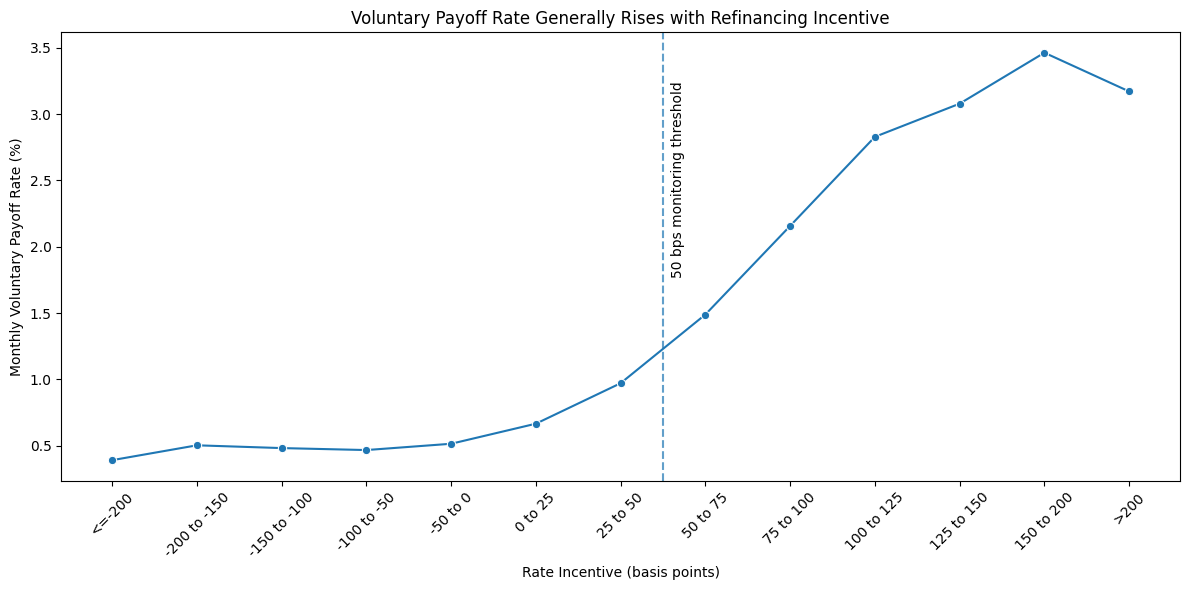

In [0]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=plot_band_summary,
    x="incentive_band",
    y="monthly_payoff_rate_pct",
    marker="o"
)

# 50 bps monitoring threshold
plt.axvline(
    x=6.5,
    linestyle="--",
    alpha=0.7
)

plt.text(
    6.6,
    3.25,
    "50 bps monitoring threshold",
    rotation=90,
    va="top"
)

plt.title(
    "Voluntary Payoff Rate Generally Rises with Refinancing Incentive"
)

plt.xlabel("Rate Incentive (basis points)")
plt.ylabel("Monthly Voluntary Payoff Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

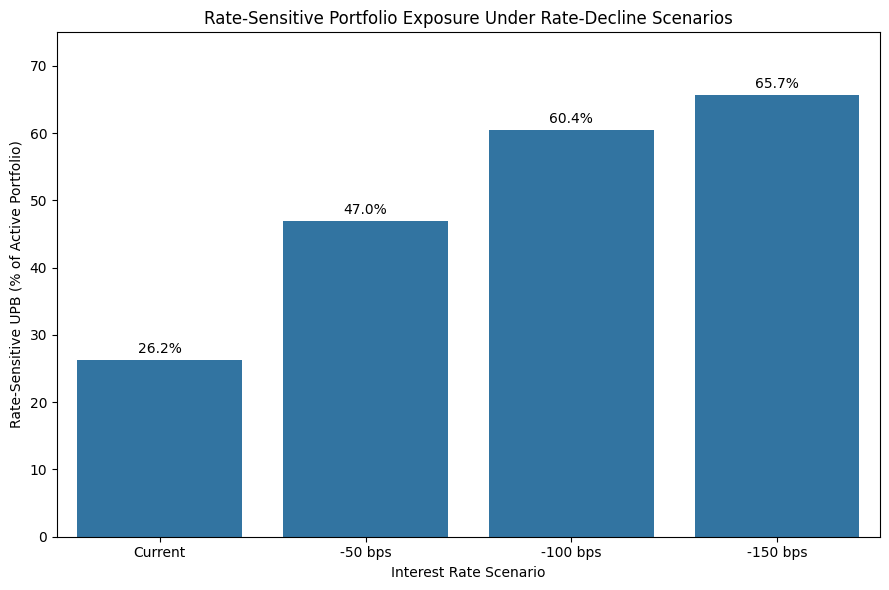

In [0]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=final_scenario_summary,
    x="scenario",
    y="rate_sensitive_upb_pct"
)

plt.title(
    "Rate-Sensitive Portfolio Exposure Under Rate-Decline Scenarios"
)

plt.xlabel("Interest Rate Scenario")
plt.ylabel("Rate-Sensitive UPB (% of Active Portfolio)")

plt.ylim(0, 75)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

- Rate-sensitive exposure increases from 26.25% of active UPB under current conditions to 46.98% after a 50-bps rate decline and 60.44% under the -100-bps scenario. The scenario results measure portfolio sensitivity rather than expected prepayment.

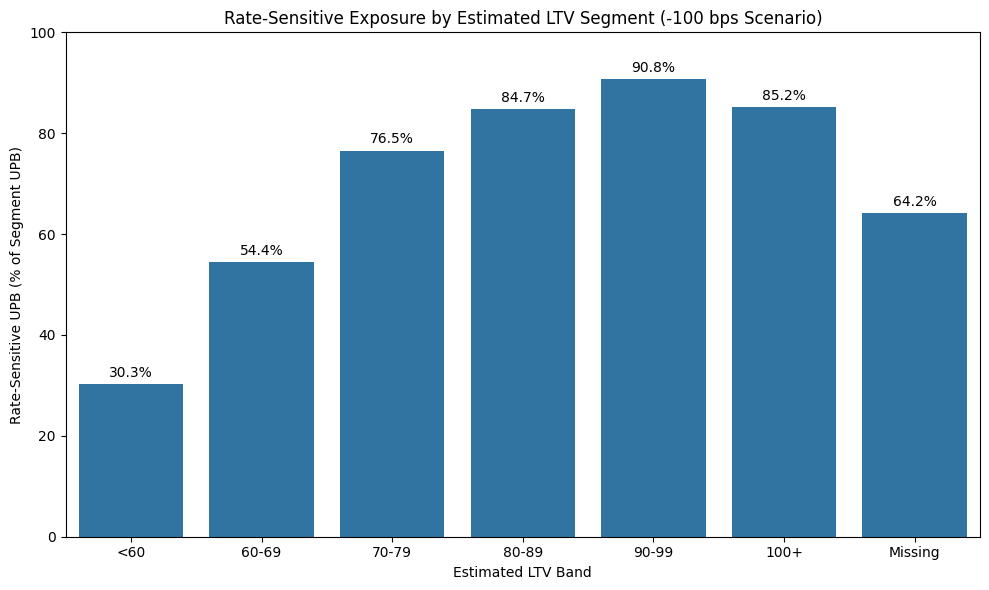

In [0]:
ltv_plot = ltv_exposure.copy()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=ltv_plot,
    x="ltv_band",
    y="exposure_intensity_pct"
)

plt.title(
    "Rate-Sensitive Exposure by Estimated LTV Segment (-100 bps Scenario)"
)

plt.xlabel("Estimated LTV Band")
plt.ylabel("Rate-Sensitive UPB (% of Segment UPB)")

plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

- Rate-sensitive exposure intensity varies across LTV segments under the -100-bps scenario, with the highest intensity observed in the 90–99 LTV segment.

- As shown in the vintage-composition analysis, this pattern partly reflects differences in cohort and mortgage-rate composition across LTV segments and should not be interpreted as a causal effect of LTV.

# 13. KEY FINDINGS AND PORTFOLIO IMPLICATIONS 

## 13.1. Refinancing Incentive Is Strongly Associated with Voluntary Payoff Behaviour

- Historical loan-month analysis shows that voluntary payoff rates generally increase as a mortgage's current interest rate rises above the prevailing 30-year market rate.

- Observed monthly voluntary payoff rates remain relatively low when refinancing incentive is negative, increase once the incentive becomes positive, and rise more materially beyond approximately 50 basis points.

- A 50-basis-point refinancing incentive is therefore used as a practical portfolio-monitoring threshold. It is an analytical threshold informed by historical behaviour in this sample, rather than an industry-standard or predictive cutoff.

## 13.2. A Decline in Mortgage Rates Could Materially Expand Rate-Sensitive Exposure

- As of March 2026, the active analytical portfolio contains 211,265 loans and approximately $62.14 billion in outstanding UPB.

- At the current 30-year PMMS rate of 6.178%, approximately $16.31 billion, or 26.25% of active UPB, meets the ≥50-bps rate-sensitive monitoring threshold.

- Under hypothetical rate declines:

    - **-50 bps:** rate-sensitive exposure increases to approximately **$29.20B (46.98%)**
    - **-100 bps:** exposure increases to approximately **$37.56B (60.44%)**
    - **-150 bps:** exposure increases to approximately **$40.84B (65.71%)**

- The -100-bps scenario therefore moves approximately **$21.25B of additional UPB** into the rate-sensitive monitoring segment relative to current conditions.

## 13.3. Exposure Is Concentrated Differently Across LTV Segments

- Under the -100-bps scenario, the **70–79 estimated-LTV segment** contains the largest dollar concentration of rate-sensitive exposure at approximately **$9.3B**.

- The **90–99 LTV segment** shows the highest exposure intensity, with approximately **90.8% of segment UPB** classified as rate-sensitive.

- However, these patterns should not be interpreted as evidence that LTV itself drives refinancing sensitivity. The LTV segments differ materially in vintage composition, with higher-LTV segments containing a greater proportion of recent vintages carrying higher mortgage coupons.

## 13.4. FICO Provides Limited Additional Differentiation

- Rate-sensitive exposure is broadly similar across the major FICO bands, with exposure intensity remaining around 59–61% for borrowers with FICO scores of 660 or above under the -100-bps scenario.

- For this portfolio sensitivity analysis, FICO therefore provides less differentiation than mortgage coupon, vintage, and estimated-LTV segmentation.

## 13.5. Portfolio Implications

- Refinancing-incentive monitoring can help portfolio managers identify how much outstanding mortgage balance moves into historically higher-prepayment segments as market rates change.

- Particular monitoring attention may be useful for portfolios with large concentrations of higher-coupon recent vintages, LTV segments containing substantial rate-sensitive exposure, and scenarios where relatively small rate declines cause large increases in the share of UPB crossing the monitoring threshold.

- The analysis supports portfolio monitoring and scenario analysis; it does not forecast individual borrower prepayments, future mortgage rates, or financial losses.

# 14. METHODOLOGY AND LIMITATIONS

## 14.1. Methodology

- The analysis uses Freddie Mac Single-Family Loan-Level Dataset sample vintages from **2019–2025**, with monthly performance records observed through **March 2026**.
- The analytical population is restricted to **30-year fixed-rate mortgages** to maintain comparability with Freddie Mac's 30-Year PMMS benchmark.
- Refinancing incentive is defined as:

  - **Current Mortgage Rate − 30-Year PMMS Rate**

  - A positive value indicates that the mortgage's current rate is above the prevailing market benchmark.
- Freddie Mac **Zero Balance Code 01** is used as a proxy for voluntary payoff after validating that observed events occur well before contractual maturity within the selected analytical population.
- Historical loan-month behaviour is used to evaluate how voluntary payoff rates vary across refinancing-incentive levels.
- A refinancing incentive of **at least 50 basis points** is used as an analytical monitoring threshold for rate-sensitive exposure.
- The March 2026 active portfolio is evaluated under hypothetical market-rate declines of **50, 100, and 150 basis points**.
- Exposure is measured using outstanding unpaid principal balance (**UPB**) and segmented by estimated LTV, vintage, and FICO.

## 14.2. Limitations

- Voluntary Payoff Is Not Equivalent to Confirmed Refinancing

  - Freddie Mac Zero Balance Code 01 identifies voluntary payoff or maturity. Within the selected 30-year mortgage population, observed Code 01 events occur well before contractual maturity, supporting their treatment as voluntary payoffs.
  - However, the dataset does not establish that every voluntary payoff resulted specifically from refinancing.

- Rate-Sensitive UPB Is an Exposure Measure, Not a Prepayment Forecast

  - A loan exceeding the 50-bps monitoring threshold is classified as rate-sensitive, but this does not imply that the borrower will prepay.

  - Scenario results therefore represent balances moving into a historically higher-prepayment segment rather than expected future prepayment volumes.

- Scenario Shocks Are Hypothetical

  - The -50, -100, and -150-bps scenarios are analytical sensitivity tests and should not be interpreted as forecasts of future mortgage rates.

- Historical Relationships Are Associative Rather Than Causal

  - Higher refinancing incentive is associated with higher observed voluntary payoff rates, but borrower behaviour may also be influenced by factors not explicitly modelled here, including housing conditions, borrower circumstances, and broader economic conditions.

- Portfolio Segments May Reflect Vintage Composition

  - Higher estimated-LTV segments contain a greater proportion of recent vintages, which also tend to carry higher mortgage coupons.

  - Differences in LTV exposure should therefore be interpreted partly as portfolio-composition patterns rather than evidence that higher LTV independently causes greater refinancing sensitivity.

- The Analysis Uses Freddie Mac Sample Data

  - The portfolio analysed in this project is constructed from Freddie Mac's publicly released loan-level mortgage dataset samples. Results therefore describe the analytical sample constructed for this project and should not be interpreted as estimates for Freddie Mac's entire mortgage portfolio or the broader U.S. mortgage market.

# 15. FINAL ANALYTICAL VALIDATION 

Perform final integrity checks on the analytical dataset and key portfolio-exposure outputs before reporting the results.

In [0]:
assert active_portfolio["loan_identifier"].is_unique
assert (active_portfolio["current_actual_upb"] > 0).all()

assert scenario_summary[
    "rate_sensitive_upb_pct"
].is_monotonic_increasing

assert np.isclose(
    active_portfolio["current_actual_upb"].sum(),
    active_upb
)

assert np.isclose(
    scenario_summary.loc[
        scenario_summary["scenario"] == "-100 bps",
        "rate_sensitive_upb"
    ].iloc[0],
    active_portfolio.loc[
        active_portfolio["scenario_rate_sensitive_flag"],
        "current_actual_upb"
    ].sum()
)

print("PASS: Final analytical outputs validated.")

PASS: Final analytical outputs validated.
